<a href="https://colab.research.google.com/github/Imperial-07/CineMatrix-SkillLab/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

3.Exploratory Data Analysis(EDA)




In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



movies = pd.read_csv('cleaned_movies.csv')
ratings = pd.read_csv('cleaned_ratings.csv')
tags = pd.read_csv('cleaned_tags.csv')


ratings['timestamp'] = pd.to_datetime(ratings['timestamp'])

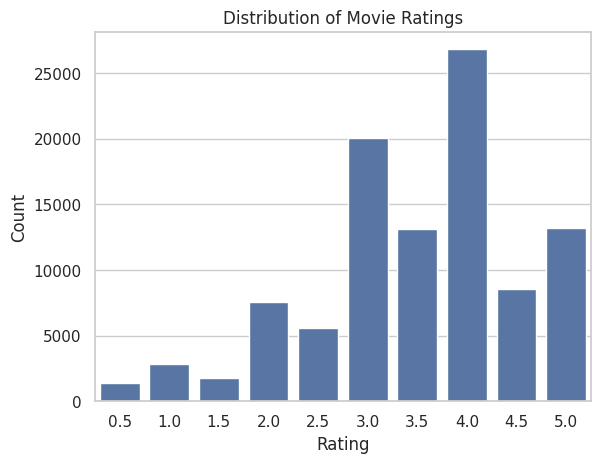

Rating Value Counts:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


In [9]:

sns.countplot(x='rating', data=ratings)
plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

print("Rating Value Counts:")
print(ratings['rating'].value_counts().sort_index())

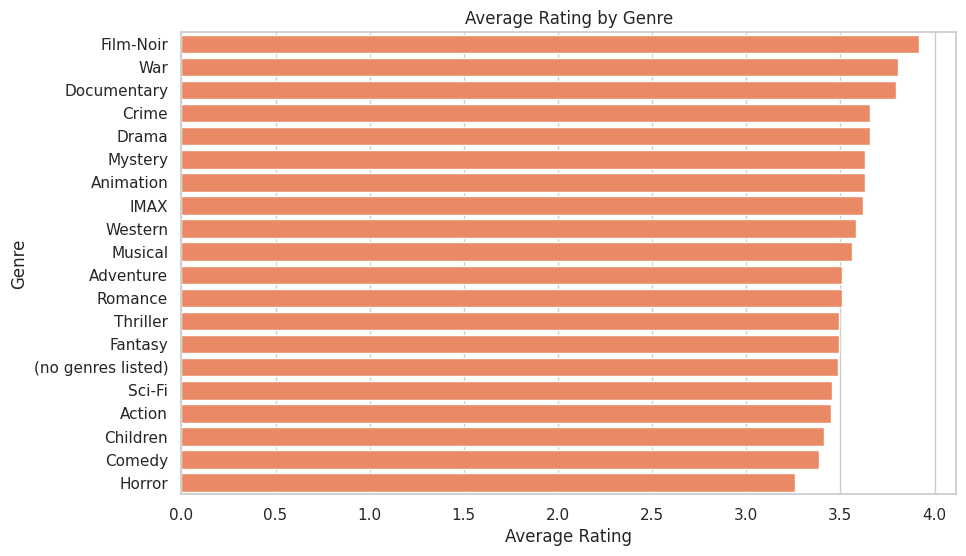

In [12]:

movies_split = movies.copy()
movies_split['genres'] = movies_split['genres'].str.split('|')
movies_split = movies_split.explode('genres')


genre_data = pd.merge(ratings, movies_split, on='movieId')

genre_avg = genre_data.groupby('genres')['rating'].mean().reset_index()
genre_avg = genre_avg.sort_values(by='rating', ascending=False)


sns.barplot(data=genre_avg, x='rating', y='genres', color='coral')
plt.title('Average Rating by Genre')
plt.xlabel('Average Rating')
plt.ylabel('Genre')
plt.show()

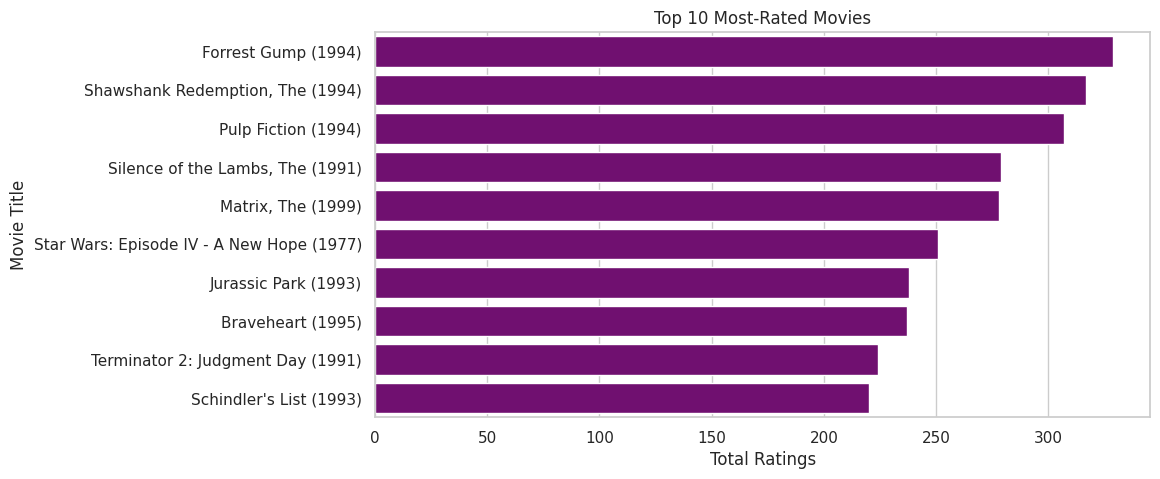

In [13]:

movie_counts = ratings.groupby('movieId').size().reset_index(name='total_ratings')

movie_counts = pd.merge(movie_counts, movies, on='movieId')


top_10 = movie_counts.sort_values(by='total_ratings', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10, x='total_ratings', y='title', color='purple')
plt.title('Top 10 Most-Rated Movies')
plt.xlabel('Total Ratings')
plt.ylabel('Movie Title')
plt.show()

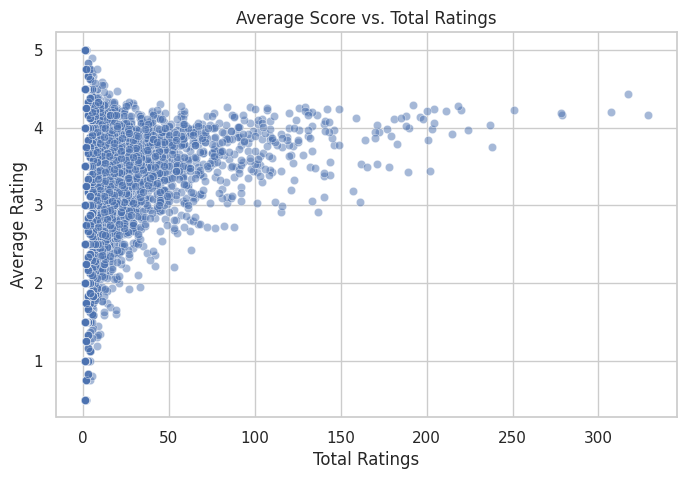

In [14]:

movie_avgs = ratings.groupby('movieId')['rating'].mean().reset_index(name='avg_rating')


movie_stats = pd.merge(movie_counts, movie_avgs, on='movieId')

plt.figure(figsize=(8, 5))
sns.scatterplot(data=movie_stats, x='total_ratings', y='avg_rating', alpha=0.5)
plt.title('Average Score vs. Total Ratings')
plt.xlabel('Total Ratings')
plt.ylabel('Average Rating')
plt.show()

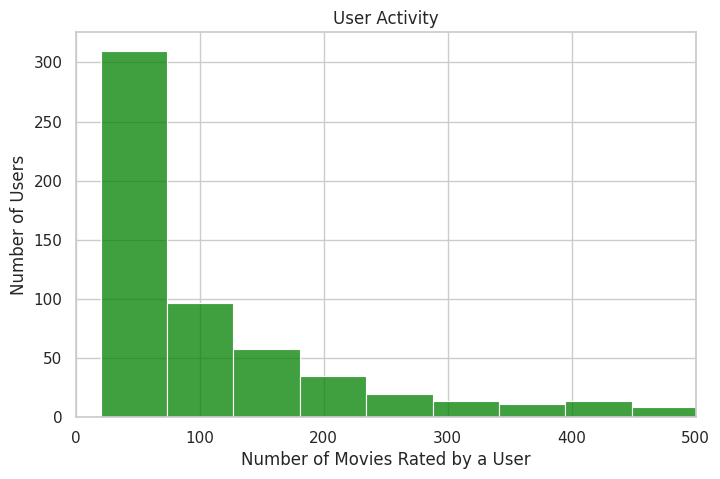

In [15]:

user_counts = ratings.groupby('userId').size()

plt.figure(figsize=(8, 5))
sns.histplot(user_counts, bins=50, color='green')
plt.title('User Activity')
plt.xlabel('Number of Movies Rated by a User')
plt.ylabel('Number of Users')
plt.xlim(0, 500)
plt.show()

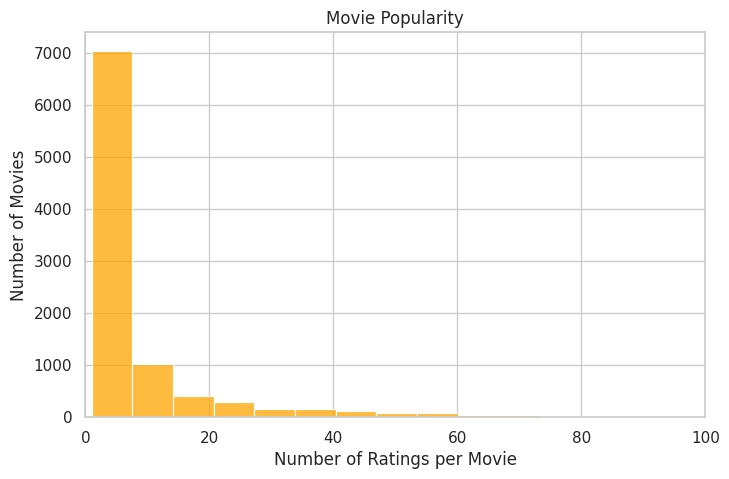

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(movie_stats['total_ratings'], bins=50, color='orange')
plt.title('Movie Popularity')
plt.xlabel('Number of Ratings per Movie')
plt.ylabel('Number of Movies')
plt.xlim(0, 100)
plt.show()

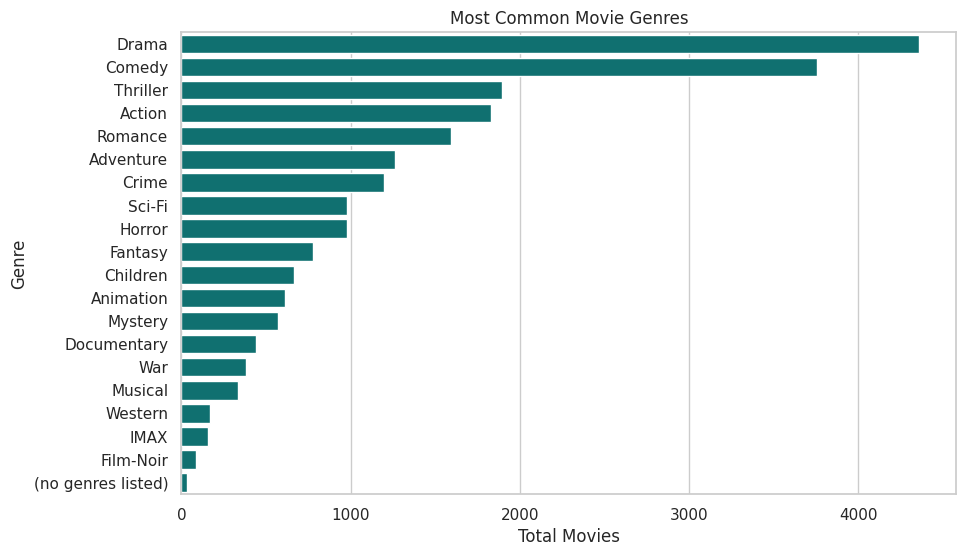

In [17]:

genre_counts = movies_split['genres'].value_counts().reset_index()
genre_counts.columns = ['genre', 'count']

plt.figure(figsize=(10, 6))
sns.barplot(data=genre_counts, x='count', y='genre', color='teal')
plt.title('Most Common Movie Genres')
plt.xlabel('Total Movies')
plt.ylabel('Genre')
plt.show()

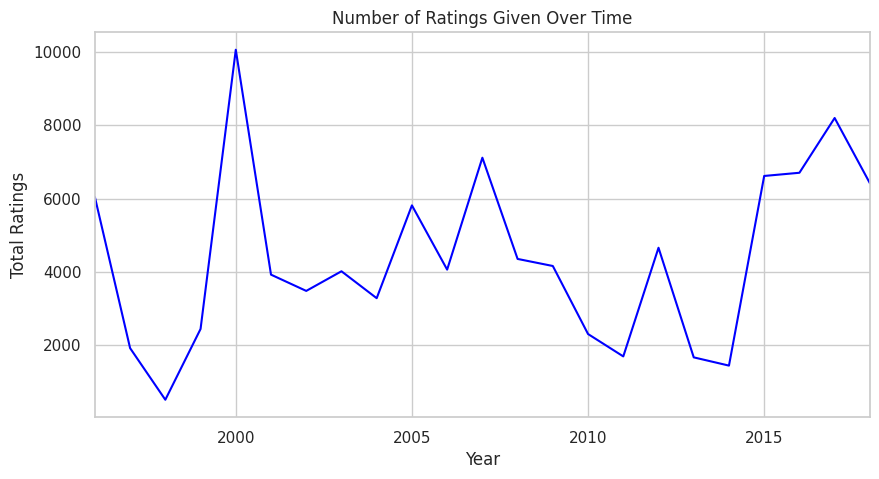

In [18]:

ratings_time = ratings.set_index('timestamp')


ratings_per_year = ratings_time.resample('YE').size()

plt.figure(figsize=(10, 5))
ratings_per_year.plot(color='blue')
plt.title('Number of Ratings Given Over Time')
plt.xlabel('Year')
plt.ylabel('Total Ratings')
plt.show()

In [19]:

unpopular_movies = (movie_stats['total_ratings'] <= 5).sum()
total_movies = len(movie_stats)

print(f"Movies with 5 or fewer ratings: {unpopular_movies}")
print(f"Total unique movies rated: {total_movies}")

min_user_ratings = user_counts.min()
print(f"The least active user still rated {min_user_ratings} movies.")

Movies with 5 or fewer ratings: 6456
Total unique movies rated: 9724
The least active user still rated 20 movies.


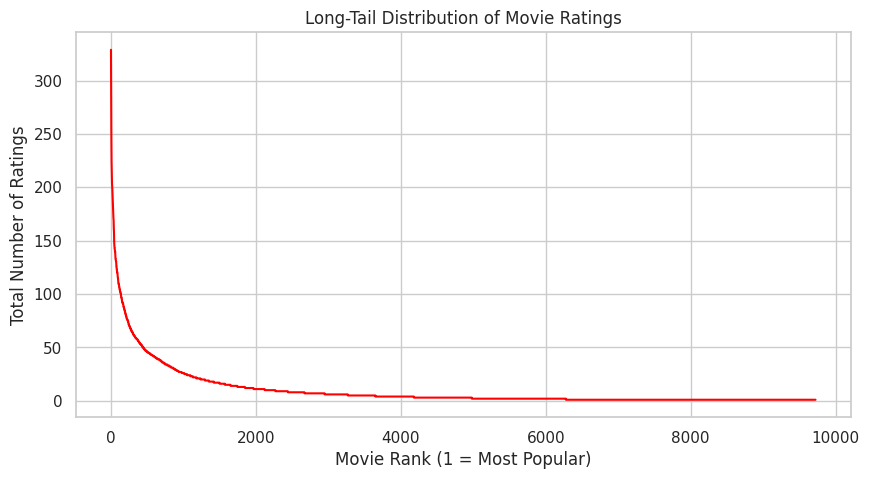

In [20]:

sorted_movies = movie_stats.sort_values(by='total_ratings', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))

plt.plot(sorted_movies.index, sorted_movies['total_ratings'], color='red')
plt.title('Long-Tail Distribution of Movie Ratings')
plt.xlabel('Movie Rank (1 = Most Popular)')
plt.ylabel('Total Number of Ratings')
plt.show()